In [1]:
# ==============================================================================
# CELL 1: CONFIG & STYLE
# ==============================================================================
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

def matplotlib_default_config():
    font = {'family': 'serif', 'weight': 'normal', 'size': 14}
    rcnew = {
        "mathtext.fontset": "cm",
        "text.usetex": False,
        'figure.frameon': True,
        'axes.linewidth': 2.,
        "axes.titlesize": 20,
        "axes.labelsize": 20,
        "legend.fontsize": 12,
        'legend.fancybox': True,
        'lines.linewidth': 2.5,
        'xtick.direction': 'in',
        'ytick.direction': 'in',
        'xtick.top': True,
        'ytick.right': True,
        'xtick.labelsize': 18,
        'ytick.labelsize': 18,
    }
    return font, rcnew

%matplotlib widget
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

PROJ_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools").is_dir())
print("project:", PROJ_ROOT)

project: /home/vroberto/FakeSpectra_DLAs


In [8]:
# ==============================================================================
# CELL 2: LOAD THE TWO RUNS
# ==============================================================================
# log_n_hi comes from colden, which the 7/8 tau bug does not touch,
# so no TAU_FIX is needed for covering fractions.

RUNS = {
    'Region growing':  PROJ_ROOT / 'data_TNG50-2_snap025_4runs',
    'Peaks + blend':   PROJ_ROOT / 'data_TNG50-2_snap025_1runs_peak_plus_blend',
}

dfs = {}
for label, d in RUNS.items():
    pkl = sorted(d.glob('*.pkl'))
    assert len(pkl) == 1, f"expected 1 pkl in {d}, found {len(pkl)}"
    df = pd.read_pickle(pkl[0])
    df['r_mult_round'] = df['r_multiplier'].round(2)
    dfs[label] = df
    print(f"{label:16s}: {len(df):>7,} skewers  |  {pkl[0].name}")

radii = np.sort(dfs['Region growing']['r_mult_round'].unique())
print(f"\nimpact parameters ({len(radii)}): {radii}")

Region growing  : 231,231 skewers  |  TNG50-2_z3_637Halos_HCDMode_Stratified_run0_seed42.pkl
Peaks + blend   : 231,231 skewers  |  TNG50-2_z3_637Halos_HCDMode_Stratified_run0_seed42.pkl

impact parameters (29): [0.000e+00 1.000e-02 2.000e-02 3.000e-02 4.000e-02 6.000e-02 8.000e-02
 1.000e-01 1.400e-01 1.900e-01 2.500e-01 3.400e-01 4.600e-01 6.100e-01
 8.200e-01 1.100e+00 1.470e+00 1.980e+00 2.650e+00 3.560e+00 4.770e+00
 6.400e+00 8.580e+00 1.151e+01 1.544e+01 2.072e+01 2.779e+01 3.728e+01
 5.000e+01]


In [9]:
# ==============================================================================
# CELL 3: COVERING FRACTIONS PER IMPACT PARAMETER
# ==============================================================================
cat_styles = {
    'Large_DLA': {'color': 'indigo',      'marker': 'v',
                  'label': r'Large DLA ($\log N_{\rm HI} \geq 21.0$)'},
    'Small_DLA': {'color': 'darkred',     'marker': 'o',
                  'label': r'Small DLA ($20.3 \leq \log N_{\rm HI} < 21.0$)'},
    'Sub_DLA':   {'color': 'darkorange',  'marker': 's',
                  'label': r'Sub-DLA ($19.0 \leq \log N_{\rm HI} < 20.3$)'},
    'LLS':       {'color': 'forestgreen', 'marker': '^',
                  'label': r'LLS ($17.2 \leq \log N_{\rm HI} < 19.0$)'},
    'Forest':    {'color': 'midnightblue','marker': 'D',
                  'label': r'Ly-$\alpha$ Forest ($\log N_{\rm HI} < 17.2$)'},
}

def covering_fractions(df, radii):
    """Fraction of skewers in each absorber class, per impact parameter."""
    out = {cat: [] for cat in cat_styles}
    for b in radii:
        n = df[df['r_mult_round'] == b]['log_n_hi'].values
        tot = len(n)
        if tot == 0:
            for cat in cat_styles:
                out[cat].append(np.nan)
            continue
        out['Large_DLA'].append(np.sum(n >= 21.0) / tot)
        out['Small_DLA'].append(np.sum((n >= 20.3) & (n < 21.0)) / tot)
        out['Sub_DLA'].append(np.sum((n >= 19.0) & (n < 20.3)) / tot)
        out['LLS'].append(np.sum((n >= 17.2) & (n < 19.0)) / tot)
        out['Forest'].append(np.sum(n < 17.2) / tot)
    return {cat: np.array(v) for cat, v in out.items()}

fracs = {label: covering_fractions(df, radii) for label, df in dfs.items()}

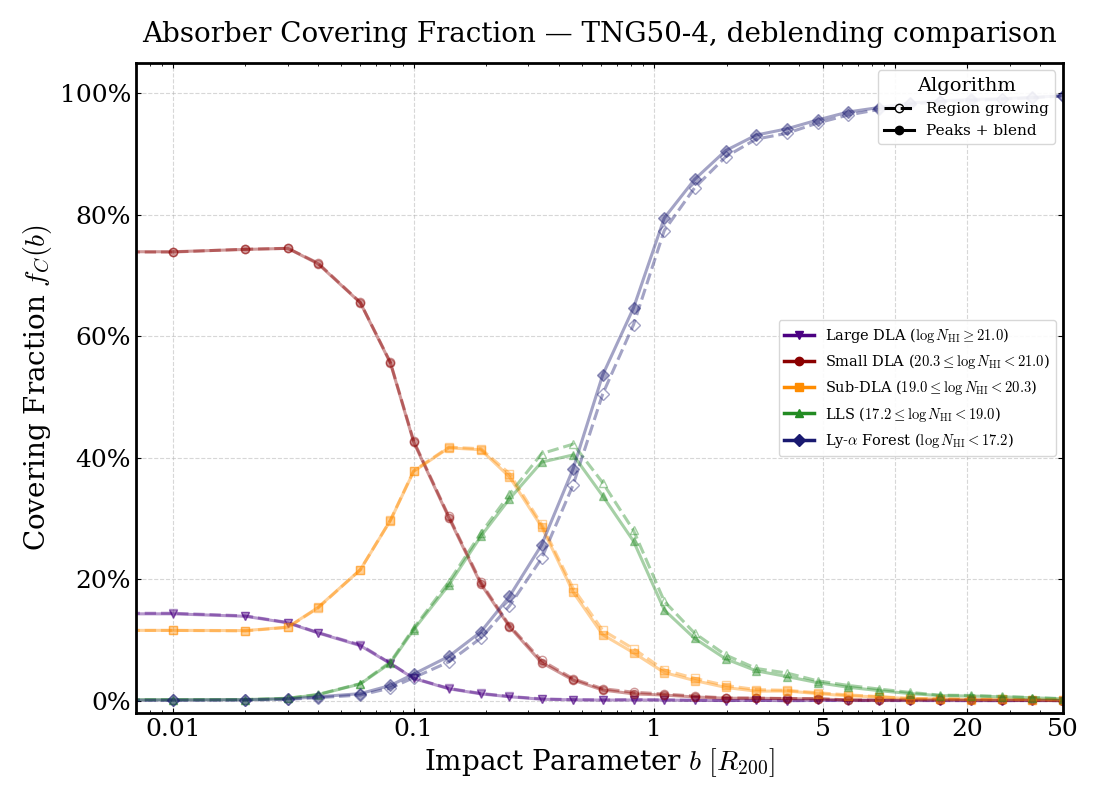

In [10]:
# ==============================================================================
# CELL 4: COMPARISON PLOT
# ==============================================================================
run_ls = {'Region growing': '--', 'Peaks + blend': '-'}
run_mfc = {'Region growing': 'none', 'Peaks + blend': None}

fig, ax = plt.subplots(figsize=(11, 8))

for label, style_ls in run_ls.items():
    for cat, st in cat_styles.items():
        ax.plot(radii, fracs[label][cat],
                color=st['color'], ls=style_ls, lw=2.2,
                marker=st['marker'], ms=6, mec=st['color'],
                mfc=run_mfc[label], alpha=0.4)

ax.grid(True, ls='--', alpha=0.5)
ax.set_xscale('log')
ax.set_ylim(-0.02, 1.05)
ax.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0))
ax.set_xticks([0.01, 0.1, 1.0, 5.0, 10.0, 20.0, 50.0])
ax.set_xticklabels(['0.01', '0.1', '1', '5', '10', '20', '50'])
ax.set_xlim(radii[radii > 0].min() * 0.7, 50)
ax.set_xlabel(r'Impact Parameter $b \ [R_{200}]$')
ax.set_ylabel(r'Covering Fraction $f_C(b)$')
ax.set_title(r'Absorber Covering Fraction — TNG50-4, deblending comparison', pad=15)

# legend 1: absorber classes (colours)
leg_cat = ax.legend(
    handles=[Line2D([0], [0], color=c['color'], lw=2.5,
                    marker=c['marker'], label=c['label'])
             for c in cat_styles.values()],
    loc='center right', frameon=True, fontsize=10.5,
    edgecolor='lightgray', facecolor='white', framealpha=0.9,
)
ax.add_artist(leg_cat)

# legend 2: pipelines (line styles)
ax.legend(
    handles=[Line2D([0], [0], color='k', ls=run_ls[l], lw=2.2,
                    marker='o', mfc=run_mfc[l], mec='k', label=l)
             for l in run_ls],
    loc='upper right', frameon=True, fontsize=11,
    edgecolor='lightgray', facecolor='white', framealpha=0.9,
    title='Algorithm',
)

plt.tight_layout()
plt.show()

In [5]:
# ==============================================================================
# CELL 5 (optional): NUMERICAL DIFFERENCE
# ==============================================================================
diff = pd.DataFrame({'b': radii})
for cat in cat_styles:
    diff[cat] = fracs['Peaks + blend'][cat] - fracs['Region growing'][cat]
pd.set_option('display.float_format', lambda x: f'{100*x:+.1f}%' if abs(x) < 1 else f'{x:.2f}')
print("Peaks+blend  minus  region growing  (percentage points):")
print(diff.to_string(index=False))

Peaks+blend  minus  region growing  (percentage points):
     b  Large_DLA  Small_DLA  Sub_DLA   LLS  Forest
 +0.0%      +0.0%      +0.0%    +0.0% +0.0%   +0.0%
 +1.0%      +0.0%      -0.0%    +0.0% +0.0%   +0.0%
 +2.0%      +0.0%      +0.0%    +0.0% +0.0%   +0.0%
 +3.0%      +0.0%      +0.0%    +0.0% +0.0%   +0.0%
 +4.0%      +0.0%      +0.0%    +0.0% +0.0%   +0.0%
 +6.0%      +0.0%      +0.0%    -0.0% +0.0%   +0.0%
 +8.0%      +0.0%      +0.0%    +0.0% +0.0%   +0.0%
+10.0%      +0.0%      +0.0%    +0.0% +0.0%   +0.0%
+14.0%      +0.0%      +0.0%    +0.0% -0.0%   +0.0%
+19.0%      +0.0%      +0.0%    +0.1% -0.1%   +0.0%
+25.0%      +0.0%      +0.0%    +0.0% +0.0%   +0.0%
+34.0%      +0.0%      +0.0%    +0.0% -0.0%   +0.0%
+46.0%      +0.0%      +0.0%    +0.0% +0.0%   -0.0%
+61.0%      +0.0%      +0.0%    +0.0% +0.0%   +0.0%
+82.0%      +0.0%      +0.0%    +0.0% +0.0%   +0.0%
  1.10      +0.0%      +0.0%    +0.0% +0.0%   +0.0%
  1.47      +0.0%      +0.0%    +0.0% +0.0%   +0.0%
  1.98 